In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy.stats import kurtosis, skew

In [2]:
#GHI É ÍNDICE DE RADIAÇÃO

df = pd.read_csv("monthly_radiation_BR_NEB.csv", index_col="time", parse_dates=True) # O argumento dentro do index_col é a coluna que vai virar index

display(df)

,GHI
time,
1991-01-01,245.446237
1991-02-01,237.562500
1991-03-01,222.413978
1991-04-01,231.050000
1991-05-01,190.873656
...,...
2025-02-01,253.288690
2025-03-01,244.830645
2025-04-01,245.834722


In [3]:
df.info()

df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 414 entries, 1991-01-01 to 2025-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GHI     414 non-null    float64
dtypes: float64(1)
memory usage: 6.5 KB


GHI    0
dtype: int64

Estatísticas básicas: 
              GHI
count  414.000000
mean   241.403321
std     31.568370
min    156.456989
25%    217.791667
50%    245.694220
75%    267.046069
max    300.309140


<function matplotlib.pyplot.show(close=None, block=None)>

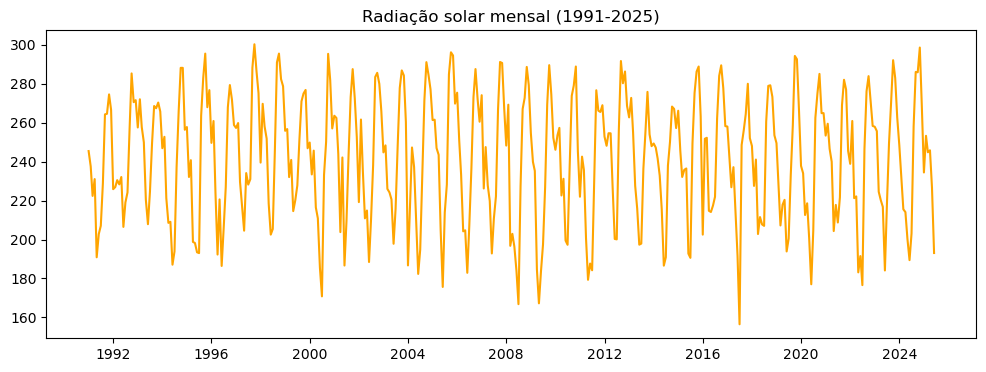

In [4]:
print("Estatísticas básicas: ")
print(df.describe())

plt.figure(figsize=(12,4))
plt.plot(df["GHI"], label="Radiação sola", color="orange")
plt.title("Radiação solar mensal (1991-2025)")
plt.grid(False)
plt.legend
plt.show

,mean,std
month,,
1,246.928034,18.225817
2,248.390278,14.731421
3,235.542089,15.059719
4,222.335000,17.621082
5,211.404071,15.774541
6,195.098810,12.993823
7,201.779096,16.758493
8,240.778582,12.546684
9,272.122059,11.020547


<Axes: xlabel='month'>

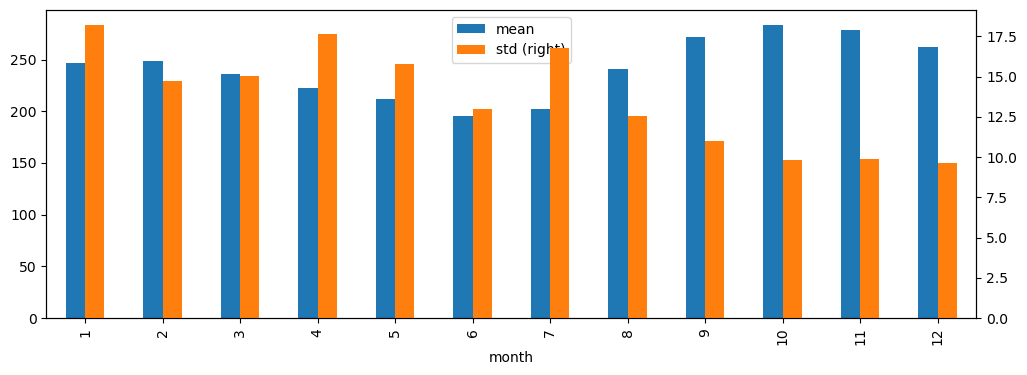

In [5]:
df["month"] = df.index.month # CRIANDO A COLUNA MONTH
df_historical = df.groupby("month")["GHI"].agg(["mean","std"]) # VISUALIZAR STD E MEAN

display(df_historical)
df_historical.plot(secondary_y="std", kind="bar", figsize=(12,4))

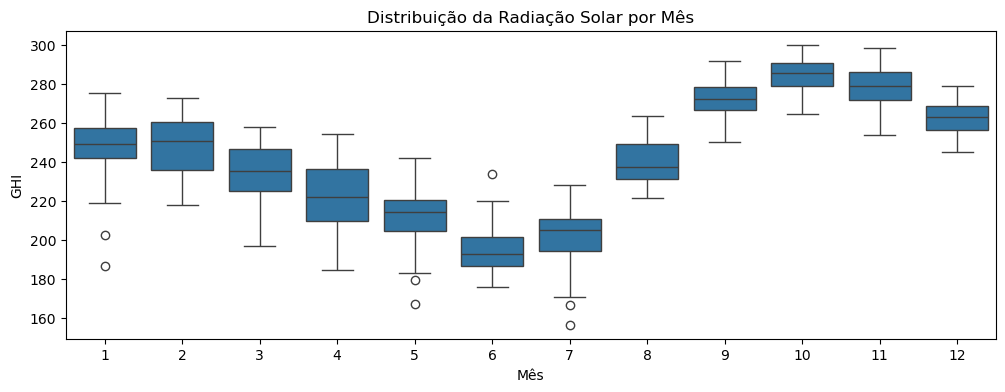

In [6]:
# BOXPLOT 

plt.figure(figsize=(12,4))
sns.boxplot(data=df, x="month", y="GHI")
plt.title("Distribuição da Radiação Solar por Mês")
plt.xlabel("Mês")
plt.show()

Estatística Avançada: 
Assimetria (skewness):  -0.25750245206479566
Curtose (kurtosis):  -0.8398033822255058


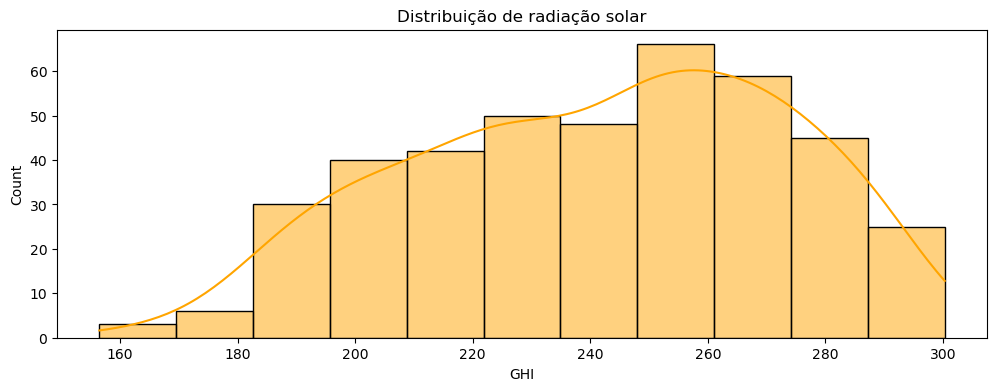

In [15]:
# DISTRIBUIÇÃO DOS DADOS: 

print("Estatística Avançada: ")
print("Assimetria (skewness): ", skew(df["GHI"]))
print("Curtose (kurtosis): ", kurtosis(df["GHI"]))

plt.figure(figsize=(12,4))
sns.histplot(data=df["GHI"], kde=True, color="orange")
plt.title("Distribuição de radiação solar")
plt.show()